# Pima: four-criterion QUBO → Advantage2 QPU → Random Forest

Select **4 of 8 original features** by combining **relevance, redundancy, interaction, and feature cost** in one QUBO. Then evaluate a Random Forest on the selected features and compare it with all eight features. The four parts below cover data preparation, QUBO construction, hardware sampling/timing, and classifier evaluation.

Run cells in order from the repository root or this notebook's folder, using the repository's `.venv` kernel. Dependencies are in this folder's `requirements.txt`; this notebook does not import the older helper script. Set the environment variable `DWAVE_API_TOKEN` to your actual Leap API token, or enter it at the hidden prompt. The token is never printed or written to a file.

`K`, `WEIGHTS`, and `FEATURE_COSTS` are editable. Their defaults are practice assumptions fixed before evaluation. Each run of Part 3 submits **one new hardware job**. An accessible, online production Advantage2 QPU is required.

In [3]:
import os
from getpass import getpass
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
from IPython.display import display
from dwave.system import DWaveSampler, EmbeddingComposite
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

K = 4
WEIGHTS = {"relevance": 1.0, "redundancy": 0.5, "interaction": 0.5, "cost": 0.25}
# Illustrative acquisition-effort units, NOT measured Pima costs or healthcare prices.
FEATURE_COSTS = {
    "Pregnancies": 1, "Glucose": 4, "BloodPressure": 1, "SkinThickness": 2,
    "Insulin": 5, "BMI": 1, "DiabetesPedigreeFunction": 2, "Age": 1,
}
NUM_READS = 1000
ANNEALING_TIME_US = 20.0
SEED = 42

## 1. Split first, then impute

**Purpose:** prepare complete training/test tables without leaking test information into selection.

Read the existing raw Pima CSV, separate its eight predictors from binary `Outcome`, and replace zero Glucose, BloodPressure, SkinThickness, Insulin, and BMI values with missing values. Zero pregnancies remains valid. Make a reproducible stratified 80/20 split so both sets retain the class proportions.

Fit the median imputer on **training rows only**, then apply those same medians to both sets. All selection scores in Part 2 also use training rows only. Random Forest does not need scaling; standardization in Part 2 is solely for the interaction calculation.

In [4]:
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
            "BMI", "DiabetesPedigreeFunction", "Age"]
relative_path = Path("data/raw/pima-indians-diabetes.csv")
data_path = next((folder / relative_path for folder in
                  [Path.cwd(), Path.cwd() / "Quantum annealing for feature selection"]
                  if (folder / relative_path).is_file()), None)
if data_path is None:
    raise FileNotFoundError("Run from the repository root or this notebook's folder.")

data = pd.read_csv(data_path, header=None, names=FEATURES + ["Outcome"])
X, y = data[FEATURES].copy(), data["Outcome"]
missing_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X[missing_columns] = X[missing_columns].replace(0, np.nan)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 614 rows | Test: 154 rows


## 2. Build the QUBO with all four criteria

**Purpose:** reward informative, complementary features while discouraging duplication and acquisition effort. Let $x_i=1$ select original feature $i$.

| Criterion | Training score | Desired direction |
|---|---|---|
| Relevance | $r_i=|\mathrm{corr}(X_i,y)|$ | Higher: a feature relates to the target |
| Redundancy | $R_{ij}=|\mathrm{corr}(X_i,X_j)|$ | Lower: selected features duplicate less information |
| Interaction | $S_{ij}=|\mathrm{corr}(z_i z_j,y)|$, with training-standardized $z_i$ | Higher: a pair's product relates to the target |
| Feature cost | $c_i=\mathrm{cost}_i/\max_j\mathrm{cost}_j$ | Lower: selected features are cheaper to acquire |

The interaction score is a **pair-product proxy**. It is not conditional mutual information or pure synergy: it may overlap with main effects and miss nonlinear relationships. Standardizing before multiplication prevents the product from depending on the raw measurement origin/scale. Constant products get score zero.

**Pima supplies no measured costs.** `FEATURE_COSTS` contains editable illustrative effort units; replace these with real costs for a cost-sensitive study. All-zero costs disable this term. With fixed `K`, equal costs add the same amount to every feasible subset and cannot change the optimum.

Minimize the weighted objective, with $C=\max(1,\binom K2)$:

$$E(x)=-\frac{\alpha}{K}\sum_i r_ix_i
+\frac{\beta}{C}\sum_{i<j}R_{ij}x_ix_j
-\frac{\gamma}{C}\sum_{i<j}S_{ij}x_ix_j
+\frac{\delta}{K}\sum_i c_ix_i
+A\left(\sum_i x_i-K\right)^2.$$

The minus signs reward relevance and interaction; plus signs penalize redundancy and cost. `WEIGHTS` sets $(\alpha,\beta,\gamma,\delta)=(1,0.5,0.5,0.25)$. Dividing by `K` and `C` balances feature and pair averages. Fix these weights before testing; any tuning belongs inside training-only validation.

Write $a_i=(-\alpha r_i+\delta c_i)/K$ and $b_{ij}=(\beta R_{ij}-\gamma S_{ij})/C$. The upper triangular QUBO has

$$Q_{ii}=a_i+A(1-2K),\qquad Q_{ij}=b_{ij}+2A\quad(i<j).$$

Count each pair once. The constant $AK^2$ is omitted because it does not affect the minimizing subset. Choose $A>\max_i(|a_i|+\sum_{j\ne i}|b_{ij}|)$: one bit flip toward size `K` reduces the penalty by more than any possible increase in the base objective. Every ideal global minimum therefore selects exactly `K` features; noisy QPU results can still violate this.

The code displays feature scores/costs and the actual QUBO coefficients. This is a four-criterion correlation surrogate, not Hall's ratio-based CFS.

In [5]:
n = len(FEATURES)
if not isinstance(K, int) or not 1 <= K <= n:
    raise ValueError("K must be an integer from 1 to 8.")
if set(WEIGHTS) != {"relevance", "redundancy", "interaction", "cost"}:
    raise ValueError("Provide all four criterion weights.")
if any(not np.isfinite(w) or w < 0 for w in WEIGHTS.values()):
    raise ValueError("Weights must be finite and nonnegative.")
if set(FEATURE_COSTS) != set(FEATURES):
    raise ValueError("Provide one cost for each feature.")
raw_cost = np.array([FEATURE_COSTS[name] for name in FEATURES], dtype=float)
if not np.isfinite(raw_cost).all() or np.any(raw_cost < 0):
    raise ValueError("Feature costs must be finite and nonnegative.")
cost = raw_cost / raw_cost.max() if raw_cost.max() else raw_cost.copy()

relevance = X_train.corrwith(y_train).abs().fillna(0).to_numpy()
redundancy = X_train.corr().abs().fillna(0).to_numpy(copy=True)
np.fill_diagonal(redundancy, 0)
z = ((X_train - X_train.mean()) / X_train.std(ddof=0).replace(0, 1)).to_numpy()

def abs_corr(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    a, b = a - a.mean(), b - b.mean()
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.clip(abs(a @ b) / denominator, 0, 1)) if denominator else 0.0

interaction = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        interaction[i, j] = interaction[j, i] = abs_corr(z[:, i] * z[:, j], y_train)

pairs = max(1, K * (K - 1) // 2)
linear = (-WEIGHTS["relevance"] * relevance + WEIGHTS["cost"] * cost) / K
pairwise = (WEIGHTS["redundancy"] * redundancy - WEIGHTS["interaction"] * interaction) / pairs
penalty = float(np.max(np.abs(linear) + np.abs(pairwise).sum(axis=1)) + 0.1)
Q = {(i, i): float(linear[i] + penalty * (1 - 2 * K)) for i in range(n)}
Q.update({(i, j): float(pairwise[i, j] + 2 * penalty)
          for i in range(n) for j in range(i + 1, n)})

display(pd.DataFrame({"Relevance": relevance, "Example cost": raw_cost,
                      "Normalized cost": cost}, index=FEATURES).round(4))
Q_table = pd.DataFrame(0.0, index=FEATURES, columns=FEATURES)
for (i, j), value in Q.items():
    Q_table.iloc[i, j] = value
print(f"Penalty A = {penalty:.6f}; QUBO constant omitted = {penalty * K**2:.6f}")
display(Q_table.round(4))

,Relevance,Example cost,Normalized cost
Pregnancies,0.2082,1.0,0.2
Glucose,0.5123,4.0,0.8
BloodPressure,0.1834,1.0,0.2
SkinThickness,0.2343,2.0,0.4
Insulin,0.2459,5.0,1.0
BMI,0.3288,1.0,0.2
DiabetesPedigreeFunction,0.1653,2.0,0.4
Age,0.2407,1.0,0.2


Penalty A = 0.292701; QUBO constant omitted = 4.683210


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,-2.0884,0.594,0.5995,0.5873,0.5884,0.5851,0.5885,0.6280
Glucose,0.0000,-2.127,0.6024,0.5987,0.6165,0.5972,0.5969,0.6067
BloodPressure,0.0000,0.000,-2.0822,0.5974,0.5879,0.6048,0.5828,0.6099
SkinThickness,0.0000,0.000,0.0000,-2.0825,0.5983,0.6297,0.5878,0.5936
Insulin,0.0000,0.000,0.0000,0.0000,-2.0479,0.6008,0.6013,0.5935
BMI,0.0000,0.000,0.0000,0.0000,0.0000,-2.1186,0.5960,0.5840
DiabetesPedigreeFunction,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,-2.0652,0.5829
Age,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,-2.0966


## 3. Sample one Advantage2 QPU and measure time

**Purpose:** solve the eight-variable QUBO on real hardware and separate reported QPU usage from observed wall time.

As checked against [D-Wave's production QPU documentation](https://docs.dwavequantum.com/en/latest/quantum_research/solver_properties_specific.html) on **15 November 2026**, **Advantage2 (Zephyr)** is the latest production generation. Filter for online `Advantage2_system...` solvers and choose the least loaded accessible system. System numbers and graph revisions identify deployments, not newer hardware generations. The actual solver identity and job ID are printed. If your account has no matching QPU, the error is explicit; there is no fallback to an older generation or CPU solver.

`EmbeddingComposite` maps the dense QUBO to physical qubit chains. Ocean selects chain strength and scales coefficients automatically. Request 1,000 reads, each with a 20 microsecond anneal. Only QUBO coefficients go to D-Wave. Keep the lowest-energy returned sample with exactly `K` selected features; do not choose samples using test accuracy. Quantum annealing is stochastic and does not guarantee the global optimum.

Timing definitions, following [D-Wave's timing documentation](https://docs.dwavequantum.com/en/latest/quantum_research/operation_timing.html):

- **Total solver wall time:** elapsed time from sampler setup through `samples.resolve()`. Includes discovery, embedding, network, queues, QPU work, and decoding; excludes token entry, data preparation, QUBO construction, client teardown, subset filtering, and Random Forest.
- **QPU access time:** API `qpu_access_time`, the reported chargeable programming/sampling time. API timing fields are in microseconds; divide by $10^6$ for seconds.
- **Total overhead:** solver wall time minus API QPU access time. This is an aggregate residual; it cannot isolate queue, network, or embedding time individually.
- **Device initialization overhead:** API `qpu_access_overhead_time`, reported separately from `qpu_access_time`. It is already part of the total-overhead residual; do not add it again.
- **QPU sampling time:** annealing, readout, and delay across reads. **Annealing only** is the reported per-read anneal time multiplied by the number of returned reads. These are components, not extra times to add to QPU access time.

Each rerun submits a new hardware job. No saved results are reused. Missing optional timing fields display as `NaN` rather than being fabricated as zero.

In [6]:
token = os.environ.get("DWAVE_API_TOKEN") or getpass("D-Wave API token: ")
try:
    solver_start = perf_counter()  # Excludes time spent entering the token.
    with DWaveSampler(token=token, solver={
        "name__regex": "Advantage2_system.*", "topology__type": "zephyr",
        "online": True, "order_by": "avg_load",
    }) as qpu:
        sampler = EmbeddingComposite(qpu, embedding_parameters={"random_seed": SEED})
        samples = sampler.sample_qubo(
            Q, num_reads=NUM_READS, annealing_time=ANNEALING_TIME_US,
            auto_scale=True, label="Pima four-criterion feature selection"
        )
        samples.resolve()  # Sampling is asynchronous; wait before stopping the clock.
        solver_wall_s = perf_counter() - solver_start
        solver_name = qpu.solver.id
        solver_identity = getattr(qpu.solver, "identity", solver_name)
finally:
    del token

timing_us = samples.info["timing"]
qpu_access_s = timing_us["qpu_access_time"] / 1e6
# This residual already includes the separately reported device initialization overhead.
overhead_s = solver_wall_s - qpu_access_s
returned_reads = int(samples.record.num_occurrences.sum())
timing_summary = pd.DataFrame({"Seconds": {
    "Total solver wall time": solver_wall_s,
    "QPU access (API)": qpu_access_s,
    "QPU programming (API)": timing_us.get("qpu_programming_time", np.nan) / 1e6,
    "QPU sampling (API)": timing_us.get("qpu_sampling_time", np.nan) / 1e6,
    "Annealing only, all returned reads": timing_us.get("qpu_anneal_time_per_sample", np.nan) * returned_reads / 1e6,
    "Total overhead (wall minus QPU access)": overhead_s,
    "Device initialization overhead (API; included above)": timing_us.get("qpu_access_overhead_time", np.nan) / 1e6,
}})
print("Solver identity:", solver_identity)
print("Job ID:", samples.info.get("problem_id", "not reported"))
print("Returned reads:", returned_reads)
display(timing_summary.round(6))

feasible = samples.filter(lambda row: sum(row.sample.values()) == K)
if not len(feasible):
    raise RuntimeError("The QPU returned no size-K sample. Try more reads or a larger penalty.")
selected = [FEATURES[i] for i in range(n) if feasible.first.sample[i]]
print("Selected features:", selected)
print("QUBO energy (constant omitted):", feasible.first.energy)
print("Selected example cost:", sum(FEATURE_COSTS[name] for name in selected))

Solver identity: Advantage2_system1;graph_id=01b03fc8dc
Job ID: b061b3ab-9e02-4c08-882f-845cd68f638a
Returned reads: 1000


/var/folders/dd/fgjsf7z56g72tz9p9d8r59840000gp/T/ipykernel_47705/1961217025.py:15: DeprecationWarning: `Solver.id` attribute meaning has changed in dwave-cloud-client 0.14.0, due to upstream API changes. Use of `Solver.identity` is now preferred.
  solver_name = qpu.solver.id


,Seconds
Total solver wall time,4.126350
QPU access (API),0.163231
QPU programming (API),0.034631
QPU sampling (API),0.128600
"Annealing only, all returned reads",0.020000
Total overhead (wall minus QPU access),3.963119
Device initialization overhead (API; included above),0.007371


Selected features: ['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']
QUBO energy (constant omitted): -4.84364341368578
Selected example cost: 8


## 4. Evaluate Random Forest

**Purpose:** measure whether the selected original features predict `Outcome` on held-out records.

Train two CPU Random Forests: one using all eight features and one using the `K` QPU-selected features. Both use the same split, training-fitted median imputation, 300 trees, `min_samples_leaf=2`, and seed 42. The classifier uses the original imputed values, not the standardized products used to score interactions.

The table reports accuracy (fraction correct), F1 (balance of positive-class precision and recall), and ROC AUC (ranking of positives above negatives, using class-1 probabilities). It also reports each subset's **illustrative** acquisition cost. The selected-model confusion matrix is `[[TN, FP], [FN, TP]]`. Classifier fit and prediction times are measured separately and are not included in the QPU wall time or overhead.

Test labels are used only in this final part. A lower QUBO energy optimizes the four chosen criteria; it need not improve Random Forest performance. One previously explored holdout split is a practice comparison, not an independent clinical evaluation or evidence of quantum speed advantage.

The graphs below compare accuracy, F1, and ROC AUC on a 0–1 scale, then show the selected-model confusion matrix as a heatmap. Each heatmap cell is a test-record count: rows are actual classes and columns are predicted classes. The graphs reuse the evaluation results; rerun the graph cell after rerunning evaluation.

In [7]:
results = []
for name, columns in {"All features": FEATURES, "QPU selected": selected}.items():
    model = RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1
    )
    fit_start = perf_counter()
    model.fit(X_train[columns], y_train)
    fit_s = perf_counter() - fit_start
    predict_start = perf_counter()
    probability = model.predict_proba(X_test[columns])[:, 1]
    predicted = (probability > 0.5).astype(int)  # Class 0 wins ties, as in model.predict().
    predict_s = perf_counter() - predict_start
    results.append({
        "Model": name, "Features": len(columns),
        "Example cost": sum(FEATURE_COSTS[column] for column in columns),
        "Accuracy": accuracy_score(y_test, predicted),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probability),
        "Fit seconds": fit_s, "Predict seconds": predict_s,
    })
    if name == "QPU selected":
        selected_model = model
        selected_confusion = confusion_matrix(y_test, predicted, labels=[0, 1])

display(pd.DataFrame(results).set_index("Model").round(4))
print("Selected-feature confusion matrix [[TN, FP], [FN, TP]]:")
print(selected_confusion)

,Features,Example cost,Accuracy,F1,ROC AUC,Fit seconds,Predict seconds
Model,,,,,,,
All features,8,17,0.7468,0.6061,0.8131,0.3267,0.0423
QPU selected,4,8,0.7532,0.6275,0.8067,0.2771,0.0394


Selected-feature confusion matrix [[TN, FP], [FN, TP]]:
[[84 16]
 [22 32]]


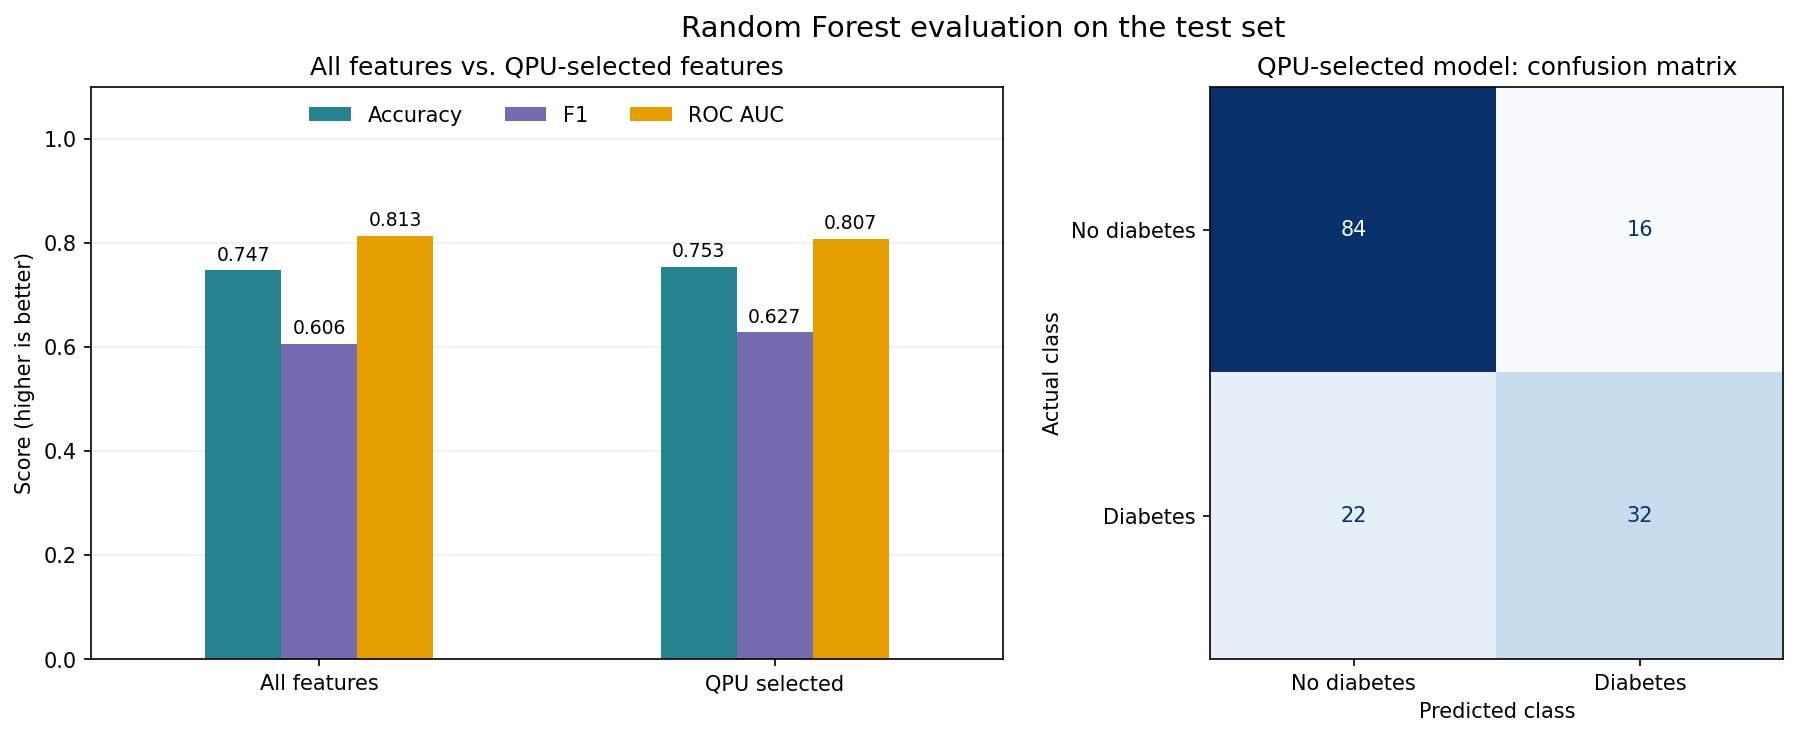

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

score_table = pd.DataFrame(results).set_index("Model")[["Accuracy", "F1", "ROC AUC"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")

score_table.plot.bar(ax=axes[0], color=["#26828e", "#756bb1", "#e69f00"], rot=0)
axes[0].set_title("All features vs. QPU-selected features")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score (higher is better)")
axes[0].set_ylim(0, 1.1)
axes[0].set_yticks(np.arange(0, 1.01, 0.2))
axes[0].set_axisbelow(True)
axes[0].grid(axis="y", alpha=0.2)
axes[0].legend(loc="upper center", ncol=3, frameon=False)
for bars in axes[0].containers:
    axes[0].bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ConfusionMatrixDisplay(
    confusion_matrix=selected_confusion,
    display_labels=["No diabetes", "Diabetes"],
).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("QPU-selected model: confusion matrix")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")
fig.suptitle("Random Forest evaluation on the test set", fontsize=14)
plt.show()

References: [production QPUs and working graphs](https://docs.dwavequantum.com/en/latest/quantum_research/solver_properties_specific.html), [solver filtering](https://docs.dwavequantum.com/en/latest/ocean/api_ref_cloud/generated/dwave.cloud.client.Client.get_solvers.html), [operation and timing](https://docs.dwavequantum.com/en/latest/quantum_research/operation_timing.html), [embedding and chain strength](https://docs.dwavequantum.com/en/latest/ocean/api_ref_system/generated/dwave.system.composites.EmbeddingComposite.sample.html), [Random Forest API](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).